# CSE 426 — Data Mining & Warehouse Lab
# Data Preprocessing — Basic to Intermediate

**Duration:** 2 hours &nbsp;|&nbsp; **Dataset:** `data/employee_attrition_raw.csv`

---

## Why preprocessing?

Real data is messy. It has blanks, typos, the same word spelled five ways,
numbers stored as text, and rows that got copied twice. A machine learning
model cannot handle any of that — it needs clean numbers.

> **Rule of thumb: 80% of a data scientist's time is spent cleaning data.**

Today we take one broken HR file and make it usable, step by step.

---

## What we will cover

| # | Topic | Minutes |
|---|---|---|
| 1 | Exploring the data | 12 |
| 2 | Missing values | 22 |
| 3 | Duplicate rows | 8 |
| 4 | Fixing data types (numbers, text, dates) | 22 |
| 5 | Inconsistent category names | 12 |
| 6 | Outliers | 15 |
| 7 | Encoding categorical data | 15 |
| 8 | Feature scaling | 8 |
| 9 | Creating new features *(optional)* | 8 |
| 10 | Train/test split + a first model | 10 |

---

## The dataset

An HR export of 1,570 employees. The goal is eventually to predict
`attrition` — did the employee leave the company (Yes/No)?

We are **not** building a good model today. We are making the data *fit to
use*. The model at the end is just proof that our cleaning worked.

In [9]:
from google.colab import drive
drive.mount('/content/drive')
# After mounting, you can access your file at:
# path = '/content/drive/MyDrive/Data mining Lab/employee_attrition_raw.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
# PART 1 — Exploring the data

**Never start cleaning before you look.** These five commands are the first
five things you type for *any* new dataset.

In [10]:
#Importing the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [11]:
path = '/content/drive/MyDrive/Data mining Lab/employee_attrition_raw.csv'
df = pd.read_csv(path)

print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (1570, 25)


In [12]:
# The first few rows
df.head()

,emp_id,full_name,gender,age,department,job_title,city,education_level,hire_date,last_promotion_date,...,num_companies_worked,overtime,job_satisfaction,performance_rating,training_hours_last_year,commute_mode,employee_survey_comment,data_source_batch,exit_interview_scheduled,attrition
0,EMP-00408,HASAN ISLAM,male,33,FINANCE,Accountant,Rangpur,Bachelors,2013-06-16,"May 28, 2018",...,2,TRUE,2,3,9,Uber/Pathao,Supportive manager,HRIS_2024,No,No
1,EMP-01181,Lamia Chowdhury,Male,41,HR,HR Manager,Dhaka,PhD,2015.07.31,"June 29, 2018",...,1,1,Medium,3,39,Bus,Supportive manager,HRIS_2024,No,Yes
2,EMP-00968,Omar Ahmed,M,41,Sales,Sales Representative,Sylhet,Masters,2007.07.27,"August 04, 2008",...,3,FALSE,Very High,3,36,Private Car,SUPPORTIVE MANAGER,HRIS_2024,No,No
3,EMP-00611,Omar Chowdhury,Male,39,Research & Development,Data Analyst,Barishal,Bachelors,2023-04-03,"December 30, 2024",...,5,No,High,3,43,Walk,Good work life balance,HRIS_2024,No,No
4,EMP-00672,HASAN MIA,MALE,37,r&d,Laboratory Technician,Cumilla,High School,29/06/2007,2011.07.13,...,2,no,1,3,28,Walk,Fair appraisal process this year,HRIS_2024,No,No


In [13]:
# Column names, data types, and how many non-null values each has
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1570 entries, 0 to 1569
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   emp_id                    1570 non-null   object 
 1   full_name                 1570 non-null   object 
 2   gender                    1533 non-null   object 
 3   age                       1570 non-null   int64  
 4   department                1570 non-null   object 
 5   job_title                 1570 non-null   object 
 6   city                      1570 non-null   object 
 7   education_level           1521 non-null   object 
 8   hire_date                 1570 non-null   object 
 9   last_promotion_date       1127 non-null   object 
 10  monthly_income            1570 non-null   object 
 11  annual_bonus_pct          1570 non-null   object 
 12  distance_from_home_km     1570 non-null   float64
 13  years_at_company          1570 non-null   object 
 14  total_wo

### Reading `info()` — what should worry you already

Look at the **Dtype** column above:

* `monthly_income` is text, but income should be a **number**.
* `age` is `int64` — good, that is a real number.
* `hire_date` is text, but a date should be a **datetime**.

> 📌 **Note on the dtype name.** On pandas 3.x text columns show as `str`; on
> pandas 2.x and earlier the same columns show as `object`. They mean the same
> thing here: *"pandas could not make this numeric, so it kept it as text."*

Any column that *should* be numeric but shows up as text has something wrong
inside it — a currency symbol, a comma, a unit, or a stray word.

In [14]:
# Summary statistics for the numeric columns
df.describe()

,age,distance_from_home_km,total_working_years,performance_rating
count,1570.000000,1570.000000,1570.000000,1570.000000
mean,27.905096,8.802420,9.944140,3.020382
std,94.721439,6.614862,5.318053,0.141349
min,-999.000000,-23.700000,0.900000,3.000000
25%,30.000000,4.200000,5.900000,3.000000
50%,36.000000,7.400000,9.850000,3.000000
75%,41.000000,11.900000,14.000000,3.000000
max,250.000000,39.200000,26.000000,4.000000


### Spot the problem in `describe()`

Look at **`age`**:

* `min` = 0 → a newborn employee?
* `max` = 250 → a 250-year-old employee?

These are impossible. Somebody typed them wrong, or the system used a code
like `-999` to mean "unknown". We will fix this in Part 6.

In [15]:
# For text columns, value_counts() is the tool. It shows every distinct value.
print("--- gender ---")
print(df["gender"].value_counts())

--- gender ---
gender
male       185
 Male      163
M          159
MALE       154
Male       153
m          134
F          113
female     100
Female      99
f           92
 female     87
FEMALE      84
missing      3
-            3
?            2
--           2
Name: count, dtype: int64


### 😱 Look at that

`gender` should have **2** values. Instead we have `Male`, `male`, `M`, `MALE`,
`Female`, `female`, `F`, ... plus junk like `?` and `missing`.

To a computer, `"Male"` and `"male"` are two completely different categories.
This is one of the most common problems in real data, and we fix it in Part 5.

In [16]:
# How many distinct values does each column have?
print("Number of unique values per column:")
print(df.nunique().sort_values())

Number of unique values per column:
data_source_batch              1
attrition                      2
performance_rating             2
exit_interview_scheduled       2
education_level                9
overtime                      10
num_companies_worked          11
commute_mode                  12
job_satisfaction              12
gender                        16
city                          20
department                    20
job_title                     27
employee_survey_comment       42
age                           45
training_hours_last_year      54
total_working_years          217
distance_from_home_km        269
years_at_company             327
full_name                    712
last_promotion_date          868
annual_bonus_pct             905
hire_date                   1458
monthly_income              1471
emp_id                      1500
dtype: int64


Two useful things jump out:

* `data_source_batch` has **1** unique value. Every row is identical, so the
  column tells us nothing. It can be deleted.
* `job_title` and `city` have many values — we will need a plan for those in
  Part 7.

---
# PART 2 — Missing values

### 2.1 Finding them

In [17]:
# isnull() gives True/False for every cell. Summing counts the Trues.
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values per column:")
print(missing)
print(f"\nTotal missing cells: {df.isnull().sum().sum()}")

Missing values per column:
last_promotion_date         443
commute_mode                 69
employee_survey_comment      58
training_hours_last_year     52
education_level              49
gender                       37
num_companies_worked         37
job_satisfaction             29
dtype: int64

Total missing cells: 774


In [18]:
# Usually the PERCENTAGE is more useful than the count
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
print("Percentage missing:")
print(missing_pct)

Percentage missing:
last_promotion_date         28.22
commute_mode                 4.39
employee_survey_comment      3.69
training_hours_last_year     3.31
education_level              3.12
gender                       2.36
num_companies_worked         2.36
job_satisfaction             1.85
dtype: float64


### 2.2 The hidden missing values ⚠️

The counts above are **wrong** — they are too low.

`pd.read_csv` only understands a few words as "missing" (like `NA` and an
empty cell). But whoever exported this file also used `?`, `missing`, `n/a`
and `--`. Pandas thinks those are perfectly good text.

In [19]:
# Look for yourself:
print("Values in 'commute_mode':")
print(df["commute_mode"].value_counts().tail(8))

Values in 'commute_mode':
commute_mode
Uber/Pathao    131
Walk            95
Bicycle         35
Train           25
?               11
-               11
--              10
missing          7
Name: count, dtype: int64


`?`, `missing`, `NULL`, `--` … these are all missing values in disguise.

**The fix:** tell `read_csv` what counts as missing, using `na_values`.

In [20]:
NULL_TOKENS = ["", " ", "NA", "N/A", "n/a", "?", "null", "NULL",
               "missing", "-", "--", "NaN", "nan", "none", "None", "-999"]

df = pd.read_csv(path, na_values=NULL_TOKENS, skipinitialspace=True)

print(f"Missing cells BEFORE (naive read) :  774")
print(f"Missing cells NOW   (with na_values): {df.isnull().sum().sum()}")
print("\nWe were missing almost half of the missing values!")

Missing cells BEFORE (naive read) :  774
Missing cells NOW   (with na_values): 1241

We were missing almost half of the missing values!


> **Lesson:** always open the CSV and look at it before trusting `read_csv`.

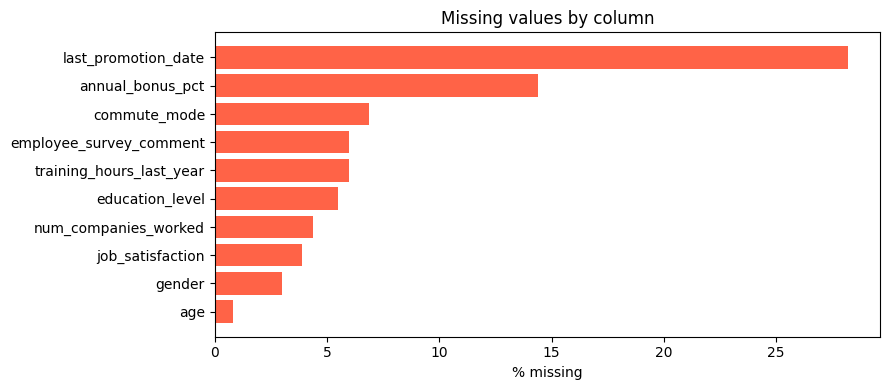

In [21]:
# A picture is easier to discuss than a table
missing_pct = (df.isnull().sum() / len(df) * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values()

plt.figure(figsize=(9, 4))
plt.barh(missing_pct.index, missing_pct.values, color="tomato")
plt.xlabel("% missing")
plt.title("Missing values by column")
plt.tight_layout()
plt.show()

### 2.3 What to DO about missing values

There are two families of solution:

| Option | Command | When to use |
|---|---|---|
| **Delete** | `dropna()` | very few missing rows, or a mostly-empty column |
| **Fill (impute)** | `fillna()` | normal case — keeps your data |

⚠️ Deleting is tempting but expensive. Watch:

In [22]:
print(f"Original number of rows      : {len(df)}")
print(f"If we drop rows with ANY NaN, remaining rows : {len(df.dropna())}")
print(f"We would throw away          : {len(df) - len(df.dropna())} rows "
      f"({(1 - len(df.dropna()) / len(df)) * 100:.0f}% of the data!)")

Original number of rows      : 1570
If we drop rows with ANY NaN, remaining rows : 661
We would throw away          : 909 rows (58% of the data!)


Deleting is almost never the right first choice. Let's fill instead.

### 2.4 Filling numeric columns: mean or median?

In [23]:
# `annual_bonus_pct` is text right now (it has a % sign), so let's use `age`,
# which is already numeric.
print("age -> missing:", df["age"].isnull().sum())
print("       mean   :", round(df["age"].mean(), 2))
print("       median :", df["age"].median())

age -> missing: 13
       mean   : 36.48
       median : 36.0


**Mean vs median — which one?**

* **Mean** is pulled around by extreme values. Remember `age` has a 250 in it!
* **Median** is the middle value, so extremes barely affect it.

👉 **Use the median when the column has outliers or is skewed. Use the mean
when the data is roughly symmetric.** When unsure, median is the safer default.

In [24]:
# Fill age with the median
df["age"] = df["age"].fillna(df["age"].median())
print("age missing after filling:", df["age"].isnull().sum())

age missing after filling: 0


> ⚠️ **Common beginner mistake:** writing `df["age"].fillna(0, inplace=True)`.
> In modern pandas this often does nothing at all. Always assign the result
> back:  `df["age"] = df["age"].fillna(...)`

### 2.5 Filling text columns: the mode

For categories there is no "average". We use the **mode** — the most frequent
value.

In [25]:
print("commute_mode missing:", df["commute_mode"].isnull().sum())   #categorical column
print("most common value   :", df["commute_mode"].mode()[0])

df["commute_mode"] = df["commute_mode"].fillna(df["commute_mode"].mode()[0])
print("missing after fill  :", df["commute_mode"].isnull().sum())

commute_mode missing: 108
most common value   : Bus
missing after fill  : 0


### 2.6 A better idea: fill with `"Unknown"`

Filling with the mode **invents** data — you are claiming those people take
the bus when you have no idea. Often it is more honest to say so:

In [26]:
df["education_level"] = df["education_level"].fillna("Unknown")
print(df["education_level"].value_counts())

education_level
Bachelors      701
Masters        386
Diploma        216
High School    121
Unknown         86
PhD             60
Name: count, dtype: int64


### 2.7 (Intermediate) Filling by group

Filling everyone's salary with the *company-wide* median is crude — an intern
and a manager get the same guess. It is much better to fill with the median
**of their own department**.

`groupby(...).transform("median")` gives each row its own group's median:

In [27]:
# A small demo on age, grouped by department
group_median = df.groupby("department")["age"].transform("median")

demo = pd.DataFrame({
    "department": df["department"],
    "age": df["age"],
    "median_age_of_their_department": group_median,
})
print(demo.head(8))

# To use it:  df["age"] = df["age"].fillna(group_median)

                 department   age  median_age_of_their_department
0                   FINANCE  33.0                            37.0
1                        HR  41.0                            35.0
2                     Sales  41.0                            36.0
3    Research & Development  39.0                            36.0
4                       r&d  37.0                            36.0
5  Research and Development  37.0                            36.0
6                       OPS   1.0                            35.0
7                     sales  42.0                            36.0


---
# PART 3 — Duplicate rows

Duplicates usually come from a bad export or a system that saved twice. They
make the model over-weight whichever rows got copied.

In [28]:
print("Number of fully duplicated rows:", df.duplicated().sum())

Number of fully duplicated rows: 48


In [29]:
# Look at a couple of them
print(df[df.duplicated(keep=False)].sort_values("emp_id").head(4).to_string())

#keep= first, only count the first occurrence
#keep= last, only count the last occurrence

        emp_id     full_name  gender   age              department          job_title   city education_level       hire_date last_promotion_date monthly_income annual_bonus_pct  distance_from_home_km years_at_company  total_working_years  num_companies_worked overtime job_satisfaction  performance_rating  training_hours_last_year commute_mode     employee_survey_comment data_source_batch exit_interview_scheduled attrition
386  EMP-00088     Imran Das  female  26.0  Research & Development  Software Engineer  Dhaka         Diploma      26/06/2021                 NaN         $7,706            8.52%                    3.4              3.5                  6.0                   1.0        0              Low                   3                      42.0          Bus          Supportive manager         HRIS_2024                       No        No
760  EMP-00088     Imran Das  female  26.0  Research & Development  Software Engineer  Dhaka         Diploma      26/06/2021                 NaN    

In [30]:
rows_before = len(df)
df = df.drop_duplicates()
print(f"Rows before: {rows_before}")
print(f"Rows after : {len(df)}")
print(f"Removed    : {rows_before - len(df)}")

Rows before: 1570
Rows after : 1522
Removed    : 48


In [31]:
# Sometimes the whole row is not identical, but the ID repeats.
# Each employee should appear only once:
print("Employees appearing more than once:", df["emp_id"].duplicated().sum())

# Keep the first record for each employee
df = df.drop_duplicates(subset="emp_id", keep="first").reset_index(drop=True)
print("After removing by emp_id, rows =", len(df))

Employees appearing more than once: 22
After removing by emp_id, rows = 1500


> `subset=` lets you decide *which columns define a duplicate*. Here, two rows
> with the same `emp_id` are the same person even if a typo makes the rows look
> different.

---
# PART 4 — Fixing data types

### 4.1 Numbers stored as text

In [32]:
print("Data type of monthly_income:", df["monthly_income"].dtype)
print("Sample values:", df["monthly_income"].head(3).tolist())

Data type of monthly_income: object
Sample values: ['$17,044', '$46,713', '$62,754']


It is text because of the `$` and the `,`. We cannot do maths on it:

In [33]:
try:
    df["monthly_income"].mean()
except Exception as e:
    print("Error:", type(e).__name__, "- cannot average text!")

Error: TypeError - cannot average text!


**The fix:** remove the unwanted characters, then convert with `astype(float)`.

In [34]:
df["monthly_income"] = (df["monthly_income"]
                        .str.replace("$", "", regex=False)
                        .str.replace(",", "", regex=False)
                        .astype(float))

print("New dtype:", df["monthly_income"].dtype)
print("Mean income:", round(df["monthly_income"].mean(), 2))

New dtype: float64
Mean income: 28793.86


In [35]:
# Same idea for the bonus percentage (it has a % sign)
df["annual_bonus_pct"] = (df["annual_bonus_pct"]
                          .str.replace("%", "", regex=False)
                          .astype(float))
print("annual_bonus_pct dtype:", df["annual_bonus_pct"].dtype)

annual_bonus_pct dtype: float64


### 4.2 When `astype` is not enough

`years_at_company` is worse — some values look like `"17.4 yrs"` and some like
`"9.4"`. Removing one fixed character will not work.

**Use `pd.to_numeric` with `errors="coerce"`**: anything it cannot convert
becomes `NaN` instead of crashing.

In [36]:
print("Sample values:", df["years_at_company"].head(5).tolist())

df["years_at_company"] = (df["years_at_company"]
                          .str.replace(" yrs", "", regex=False))
df["years_at_company"] = pd.to_numeric(df["years_at_company"], errors="coerce")

print("New dtype:", df["years_at_company"].dtype)
print("Failed to convert (now NaN):", df["years_at_company"].isnull().sum())

Sample values: ['11.5', '9.4', '17.4', '1.7', '17.5']
New dtype: float64
Failed to convert (now NaN): 0


In [37]:
# Convert the remaining number-columns the same safe way
for col in ["total_working_years", "num_companies_worked",
            "training_hours_last_year", "distance_from_home_km"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[["monthly_income", "years_at_company", "total_working_years",
          "training_hours_last_year"]].dtypes)

monthly_income              float64
years_at_company            float64
total_working_years         float64
training_hours_last_year    float64
dtype: object


### 4.3 Cleaning text columns

Three string methods do 90% of text cleaning:

| Method | What it does |
|---|---|
| `.str.strip()` | removes spaces at the start and end |
| `.str.lower()` / `.str.title()` | fixes capitalisation |
| `.str.replace(a, b)` | swaps text |

In [38]:
print("Before:", repr(df["full_name"].iloc[1]))  #loc= index no. iloc=position
df["full_name"] = df["full_name"].str.strip().str.title()
print("After :", repr(df["full_name"].iloc[1]))

Before: 'Lamia Chowdhury'
After : 'Lamia Chowdhury'


### 4.4 Dates

`hire_date` is text. Once converted with `pd.to_datetime`, we can subtract
dates, extract the year, sort chronologically, and so on.

This file stores dates in several different formats, so we add
`format="mixed"`. `dayfirst=True` tells pandas that `05/03/2020` means
5 March, not 3 May.

In [39]:
print("Before:", df["hire_date"].head(4).tolist())

df["hire_date"] = pd.to_datetime(df["hire_date"], format="mixed", dayfirst=True)

print("After :", df["hire_date"].head(4).tolist())
print("Dtype :", df["hire_date"].dtype)

Before: ['2013-06-16', '2015.07.31', '2007.07.27', '2023-04-03']
After : [Timestamp('2013-06-16 00:00:00'), Timestamp('2015-07-31 00:00:00'), Timestamp('2007-07-27 00:00:00'), Timestamp('2023-04-03 00:00:00')]
Dtype : datetime64[ns]


In [40]:
# Now we can pull useful pieces out of the date
df["hire_year"] = df["hire_date"].dt.year
df["hire_month"] = df["hire_date"].dt.month

print(df[["hire_date", "hire_year", "hire_month"]].head())

   hire_date  hire_year  hire_month
0 2013-06-16       2013           6
1 2015-07-31       2015           7
2 2007-07-27       2007           7
3 2023-04-03       2023           4
4 2007-06-29       2007           6


---
# PART 5 — Inconsistent category names

Back to the `gender` problem from Part 1.

In [41]:
print(df["gender"].value_counts())

gender
female    181
male      174
Male      158
M         151
MALE      149
Male      142
m         129
F         105
Female     96
f          88
FEMALE     82
Name: count, dtype: int64


### Step 1 — normalise the text

Strip the spaces and make everything lowercase. This alone removes most of
the mess.

In [42]:
df["gender"] = df["gender"].str.strip().str.lower()
print(df["gender"].value_counts())

gender
male      623
female    359
m         280
f         193
Name: count, dtype: int64


From 11 categories down to 4. The remaining problem is that `m` and `male`
mean the same thing.

### Step 2 — map the leftovers by hand

`.replace()` with a dictionary lets you say exactly what becomes what.

> 💡 **Do this by hand, not automatically.** If you let a program guess, it
> will eventually decide that "Sales" and "Sales Support" are the same thing
> and quietly destroy your data.

In [43]:
gender_map = {"m": "Male", "male": "Male", "f": "Female", "female": "Female"}
df["gender"] = df["gender"].replace(gender_map)

print(df["gender"].value_counts())

gender
Male      903
Female    552
Name: count, dtype: int64


In [44]:
# Same treatment for department
print("BEFORE:", df["department"].nunique(), "categories")

df["department"] = df["department"].str.strip().str.lower()
department_map = {
    "sales": "Sales",
    "r&d": "R&D",
    "research & development": "R&D",
    "research and development": "R&D",
    "hr": "HR",
    "human resources": "HR",
    "finance": "Finance",
    "ops": "Operations",
    "operations": "Operations",
}
df["department"] = df["department"].replace(department_map)

print("AFTER :", df["department"].nunique(), "categories")
print(df["department"].value_counts())

BEFORE: 19 categories
AFTER : 5 categories
department
R&D           577
Sales         449
Operations    198
Finance       177
HR             99
Name: count, dtype: int64


In [45]:
# And for overtime, which uses Yes / yes / Y / 1 / TRUE for the same thing
df["overtime"] = df["overtime"].str.strip().str.lower()
df["overtime"] = df["overtime"].replace(
    {"yes": "Yes", "y": "Yes", "1": "Yes", "true": "Yes",
     "no": "No", "n": "No", "0": "No", "false": "No"})
print(df["overtime"].value_counts())

overtime
No     1091
Yes     409
Name: count, dtype: int64


---
# PART 6 — Outliers

An **outlier** is a value far away from the rest. There are two kinds and they
need opposite treatment:

1. **Errors** — `age = 250`. Impossible. Remove or fix.
2. **Real extremes** — a director earning 10× the average. Real, so keep it.

### 6.1 Finding them by looking

In [46]:
print(df["age"].describe())

count    1500.000000
mean       36.546000
std        12.905099
min         0.000000
25%        30.000000
50%        36.000000
75%        41.000000
max       250.000000
Name: age, dtype: float64


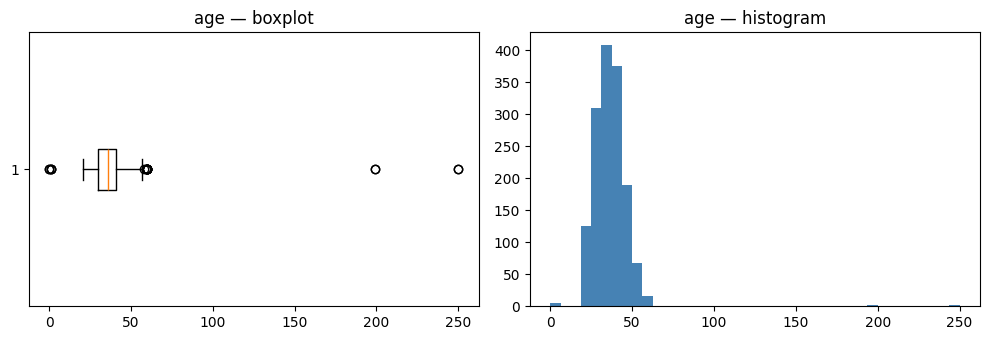

In [47]:
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.boxplot(df["age"].dropna(), vert=False)
plt.title("age — boxplot")
plt.subplot(1, 2, 2)
plt.hist(df["age"].dropna(), bins=40, color="steelblue")
plt.title("age — histogram")
plt.tight_layout()
plt.show()

The boxplot's dots on the far right are the impossible ages. The histogram is
squashed because one value of 250 stretches the whole axis.

### 6.2 Fixing the impossible values

We *know* an employee's age must be between 18 and 70. Anything outside that
is an error, so we set it to `NaN` and then fill it like any other missing
value.

In [48]:
impossible = (df["age"] < 18) | (df["age"] > 70)
print("Impossible ages found:", impossible.sum())

df.loc[impossible, "age"] = np.nan
df["age"] = df["age"].fillna(df["age"].median())

print(df["age"].describe())

Impossible ages found: 9
count    1500.000000
mean       36.161333
std         8.129085
min        21.000000
25%        30.000000
50%        36.000000
75%        41.000000
max        60.000000
Name: age, dtype: float64


In [49]:
# distance_from_home_km has negative values - distance cannot be negative.
print("Negative distances:", (df["distance_from_home_km"] < 0).sum())
df["distance_from_home_km"] = df["distance_from_home_km"].abs()
print("After abs(), minimum =", df["distance_from_home_km"].min())

Negative distances: 14
After abs(), minimum = 0.5


### 6.3 The IQR method — a rule for finding outliers

The most common statistical rule. **IQR** = Inter-Quartile Range:

```
Q1  = 25th percentile
Q3  = 75th percentile
IQR = Q3 - Q1

lower bound = Q1 - 1.5 * IQR
upper bound = Q3 + 1.5 * IQR
```

Anything outside those bounds is flagged as an outlier. (This is exactly what
the whiskers on a boxplot draw.)

In [50]:
def find_outliers_iqr(series):
    """Return the lower bound, upper bound, and a True/False outlier mask."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return lower, upper, mask


low, high, outliers = find_outliers_iqr(df["monthly_income"])

print(f"Q1 - 1.5*IQR = {low:,.0f}")
print(f"Q3 + 1.5*IQR = {high:,.0f}")
print(f"Outliers found: {outliers.sum()} rows "
      f"({outliers.sum() / len(df) * 100:.1f}%)")
print(f"Highest income in the data: {df['monthly_income'].max():,.0f}")

Q1 - 1.5*IQR = -2,719
Q3 + 1.5*IQR = 52,725
Outliers found: 61 rows (4.1%)
Highest income in the data: 752,005


### 6.4 Treating them: **capping** beats deleting

These high salaries are probably real (directors exist). Deleting the rows
would throw away real employees. Instead we **cap** them at the boundary —
also called *clipping* or *winsorising*. Every row is kept; only the extreme
leverage is removed.

In [51]:
print("BEFORE capping:")
print(f"  max  = {df['monthly_income'].max():,.0f}")
print(f"  mean = {df['monthly_income'].mean():,.0f}")

df["monthly_income"] = df["monthly_income"].clip(lower=low, upper=high)

print("\nAFTER capping:")
print(f"  max  = {df['monthly_income'].max():,.0f}")
print(f"  mean = {df['monthly_income'].mean():,.0f}")

BEFORE capping:
  max  = 752,005
  mean = 28,794

AFTER capping:
  max  = 52,725
  mean = 26,155


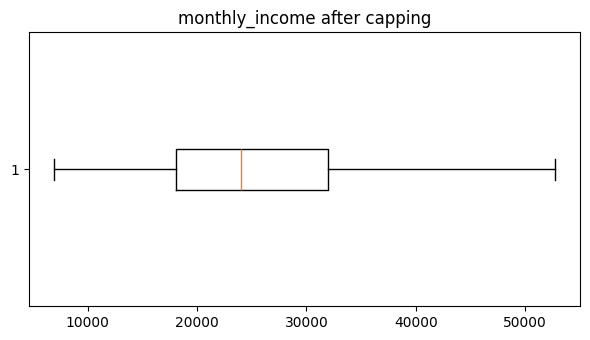

In [52]:
plt.figure(figsize=(6, 3.5))
plt.boxplot(df["monthly_income"], vert=False)
plt.title("monthly_income after capping")
plt.tight_layout()
plt.show()

---
# PART 7 — Encoding categorical data

Models only understand numbers. `"Sales"` must become a number. **How** we do
that depends on whether the categories have an order.

### 7.1 Binary columns → `map()`

Two values, so just pick 0 and 1.

In [53]:
df["overtime_num"] = df["overtime"].map({"Yes": 1, "No": 0})
df["gender_num"] = df["gender"].map({"Male": 1, "Female": 0})

print(df[["overtime", "overtime_num", "gender", "gender_num"]].head())

  overtime  overtime_num gender  gender_num
0      Yes             1   Male         1.0
1      Yes             1   Male         1.0
2       No             0   Male         1.0
3       No             0   Male         1.0
4       No             0   Male         1.0


### 7.2 Ordered categories → ordinal encoding

`education_level` **has** an order: PhD is higher than Masters, which is higher
than Bachelors. So the numbers should respect that order.

In [54]:
education_map = {
    "Unknown": 0,
    "High School": 1,
    "Diploma": 2,
    "Bachelors": 3,
    "Masters": 4,
    "PhD": 5,
}
df["education_num"] = df["education_level"].map(education_map)

print(df[["education_level", "education_num"]].drop_duplicates()
      .sort_values("education_num"))

   education_level  education_num
27         Unknown              0
4      High School              1
5          Diploma              2
0        Bachelors              3
2          Masters              4
1              PhD              5


### 7.3 Unordered categories → one-hot encoding

`department` has **no** order. Sales is not "more" than Finance.

❌ If we encoded Sales=1, R&D=2, HR=3, the model would think HR is three times
Sales, and that R&D sits exactly between them. That is nonsense.

✅ **One-hot encoding** creates a separate 0/1 column for each category.

In [55]:
dept_dummies = pd.get_dummies(df["department"], prefix="dept")
print(dept_dummies.head())

   dept_Finance  dept_HR  dept_Operations  dept_R&D  dept_Sales
0          True    False            False     False       False
1         False     True            False     False       False
2         False    False            False     False        True
3         False    False            False      True       False
4         False    False            False      True       False


In [56]:
# drop_first=True removes one column. It is redundant: if all the others are 0,
# the dropped one must be 1. This avoids the "dummy variable trap".
dept_dummies = pd.get_dummies(df["department"], prefix="dept",
                              drop_first=True, dtype=int)
df = pd.concat([df, dept_dummies], axis=1)

print("New columns added:", list(dept_dummies.columns))

New columns added: ['dept_HR', 'dept_Operations', 'dept_R&D', 'dept_Sales']


### 7.4 A warning about `LabelEncoder`

`LabelEncoder` turns categories into 0, 1, 2, 3… Many tutorials use it for
everything. **Don't.** It invents an order that does not exist — the same
mistake we just avoided.

👉 Use `LabelEncoder` only for the **target column** (the thing you predict),
where it is just a label, never for input features.

In [57]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["attrition_num"] = le.fit_transform(df["attrition"])

print("Classes found:", list(le.classes_))
print(df[["attrition", "attrition_num"]].value_counts())

Classes found: ['No', 'Yes']
attrition  attrition_num
No         0                1249
Yes        1                 251
Name: count, dtype: int64


### 7.5 What about `job_title` and `city`?

They have 27 and 20 categories. One-hot encoding would add 45 columns to a
1,500-row dataset — too many. Handling high-cardinality columns properly
(frequency encoding, target encoding) is a topic for the advanced lab. For
today we simply leave them out of the model.

---
# PART 8 — Feature scaling

Look at the ranges of our numeric columns:

In [58]:
numeric_cols = ["age", "monthly_income", "distance_from_home_km",
                "years_at_company", "training_hours_last_year"]
print(df[numeric_cols].describe().loc[["min", "max", "mean"]].round(1))

       age  monthly_income  distance_from_home_km  years_at_company  \
min   21.0          6895.0                    0.5               0.1   
max   60.0         52724.8                   39.2              18.0   
mean  36.2         26154.6                    9.0               8.7   

      training_hours_last_year  
min                        3.0  
max                       53.0  
mean                      26.9  


`monthly_income` runs into the tens of thousands; `age` only reaches 60.

Algorithms that measure **distance** (KNN, K-Means, SVM) would let income
completely dominate age, just because its numbers are bigger. Scaling puts
every column on a comparable range.

| Scaler | Formula | Result |
|---|---|---|
| `MinMaxScaler` | (x − min) / (max − min) | everything between **0 and 1** |
| `StandardScaler` | (x − mean) / std | mean **0**, standard deviation **1** |

**Which models need scaling?**

* ✅ **Yes:** KNN, K-Means, SVM, Logistic/Linear Regression, Neural Networks, PCA
* ❌ **No:** Decision Trees, Random Forest (they split one column at a time,
  so the scale does not matter)

In [59]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Fill any remaining gaps first — scalers cannot handle NaN
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

minmax = MinMaxScaler()
scaled_minmax = pd.DataFrame(minmax.fit_transform(df[numeric_cols]),
                             columns=numeric_cols)
print("--- After MinMaxScaler (everything 0 to 1) ---")
print(scaled_minmax.describe().loc[["min", "max", "mean"]].round(2))

--- After MinMaxScaler (everything 0 to 1) ---
       age  monthly_income  distance_from_home_km  years_at_company  \
min   0.00            0.00                   0.00              0.00   
max   1.00            1.00                   1.00              1.00   
mean  0.39            0.42                   0.22              0.48   

      training_hours_last_year  
min                       0.00  
max                       1.00  
mean                      0.48  


In [60]:
standard = StandardScaler()
scaled_standard = pd.DataFrame(standard.fit_transform(df[numeric_cols]),
                               columns=numeric_cols)
print("--- After StandardScaler (mean 0, std 1) ---")
print(scaled_standard.describe().loc[["mean", "std", "min", "max"]].round(2))

--- After StandardScaler (mean 0, std 1) ---
       age  monthly_income  distance_from_home_km  years_at_company  \
mean  0.00           -0.00                   0.00             -0.00   
std   1.00            1.00                   1.00              1.00   
min  -1.87           -1.76                  -1.33             -1.66   
max   2.93            2.43                   4.72              1.80   

      training_hours_last_year  
mean                     -0.00  
std                       1.00  
min                      -2.49  
max                       2.72  


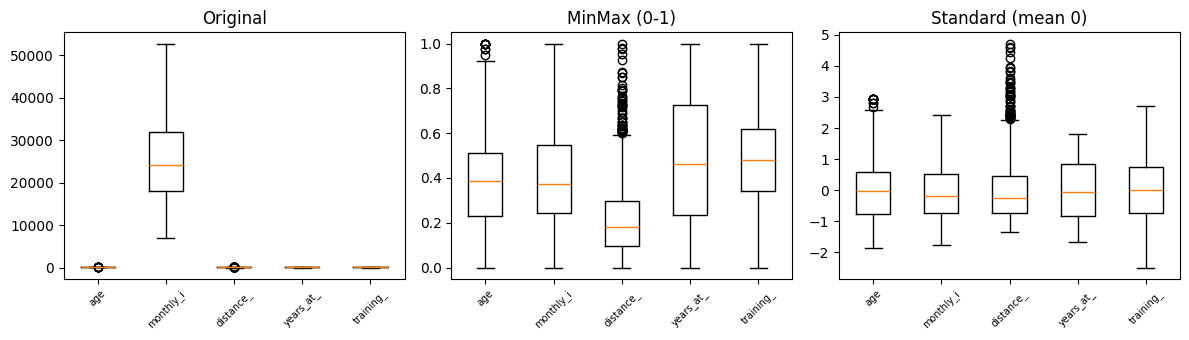

In [61]:
plt.figure(figsize=(12, 3.5))
for i, (title, data) in enumerate([("Original", df[numeric_cols]),
                                   ("MinMax (0-1)", scaled_minmax),
                                   ("Standard (mean 0)", scaled_standard)]):
    plt.subplot(1, 3, i + 1)
    plt.boxplot(data.values, tick_labels=[c[:9] for c in numeric_cols])
    plt.xticks(rotation=45, fontsize=7)
    plt.title(title)
plt.tight_layout()
plt.show()

---
# PART 9 — Creating new features *(optional if time is short)*

Often the most useful column is one that is not in the file yet. This is
called **feature engineering**.

In [62]:
# 1. Age groups, using pd.cut to turn a number into categories
df["age_group"] = pd.cut(df["age"],
                         bins=[0, 30, 40, 50, 100],
                         labels=["Under 30", "30-39", "40-49", "50+"])
print(df["age_group"].value_counts().sort_index())

age_group
Under 30    392
30-39       672
40-49       372
50+          64
Name: count, dtype: int64


In [63]:
# 2. A ratio: how much of their career has been at THIS company?
df["loyalty_ratio"] = (df["years_at_company"]
                       / df["total_working_years"].clip(lower=0.5))
print(df[["years_at_company", "total_working_years", "loyalty_ratio"]].head())

   years_at_company  total_working_years  loyalty_ratio
0              11.5                 13.0       0.884615
1               9.4                 13.0       0.723077
2              17.4                 17.8       0.977528
3               1.7                  3.5       0.485714
4              17.5                 17.0       1.029412


In [64]:
# 3. A flag: is this person a new joiner?
df["is_new_joiner"] = (df["years_at_company"] < 1).astype(int)
print(df["is_new_joiner"].value_counts())

is_new_joiner
0    1412
1      88
Name: count, dtype: int64


In [65]:
# Do the new features relate to attrition? A quick check with groupby:
print("Attrition rate by age group:")
print(df.groupby("age_group", observed=True)["attrition_num"].mean().round(3))

Attrition rate by age group:
age_group
Under 30    0.194
30-39       0.165
40-49       0.145
50+         0.156
Name: attrition_num, dtype: float64


---
# PART 10 — Train/test split and a first model

### 10.1 Final tidy-up

A few numeric columns still have gaps — the ones we converted with
`errors="coerce"` in Part 4, where unreadable text became `NaN`. Models cannot
accept `NaN`, so let's finish the job with the median.

> ⚠️ Do **not** be tempted to write `.fillna(0)` here. Zero is a real, meaningful
> number: it would claim these people have 0 years of experience and 0 training
> hours. The median is a far more honest guess.

In [66]:
still_missing = df.select_dtypes(include="number").isnull().sum()
print("Numeric columns still missing values:")
print(still_missing[still_missing > 0])

num_cols_all = df.select_dtypes(include="number").columns
df[num_cols_all] = df[num_cols_all].fillna(df[num_cols_all].median())

print("\nMissing numeric values now:", int(df[num_cols_all].isnull().sum().sum()))

Numeric columns still missing values:
annual_bonus_pct        214
num_companies_worked     67
gender_num               45
dtype: int64

Missing numeric values now: 0


### 10.2 One column we must throw away ⚠️

`exit_interview_scheduled` looks like a fantastic predictor. It is not — it is
**cheating**.

HR only schedules an exit interview *after* an employee has already resigned.
So this column is telling us the answer. When we later use the model on
current employees to guess who *might* leave, the value will always be "No"
and the model will be useless.

This is called **data leakage**, and it is the single most common way real
projects fail. The test is simple:

> **"At the moment I need the prediction, would I actually know this value?"**

If the answer is no, drop the column.

In [67]:
print("Proof - attrition rate for each value:")
print(df.groupby("exit_interview_scheduled")["attrition_num"].mean().round(3))
print("\nAlmost 0% vs almost 100%. Far too good to be true -> drop it.")

Proof - attrition rate for each value:
exit_interview_scheduled
No     0.017
Yes    0.931
Name: attrition_num, dtype: float64

Almost 0% vs almost 100%. Far too good to be true -> drop it.


### 10.3 Splitting the data

We train on one part of the data and test on another part the model has never
seen. Otherwise we are just checking whether it memorised the answers.

`stratify=y` keeps the same Yes/No proportion in both halves.

In [68]:
from sklearn.model_selection import train_test_split

feature_cols = (["age", "monthly_income", "distance_from_home_km",
                 "years_at_company", "total_working_years",
                 "num_companies_worked", "training_hours_last_year",
                 "overtime_num", "gender_num", "education_num",
                 "loyalty_ratio", "is_new_joiner"]
                + list(dept_dummies.columns))

X = df[feature_cols]
y = df["attrition_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set    : {X_test.shape[0]} rows")
print(f"Features    : {X_train.shape[1]}")

Training set: 1200 rows
Test set    : 300 rows
Features    : 16


### 10.4 Train a model

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Scale, because logistic regression is sensitive to scale.
# IMPORTANT: fit the scaler on the TRAINING data only, then apply it to the test
# data. If the scaler sees the test set, information leaks across the split.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + apply
X_test_scaled = scaler.transform(X_test)         # apply only

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")

Accuracy: 0.837


### 10.5 Careful - accuracy can lie

In [70]:
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred,
                                  target_names=["Stayed", "Left"], digits=3))

print(f"\nOnly {y.mean() * 100:.0f}% of employees actually left.")
print(f"A lazy model that always predicts 'Stayed' would score "
      f"{(1 - y.mean()) * 100:.0f}% accuracy -- without learning anything!")
print("\nThis is called CLASS IMBALANCE. Look at 'recall' for the 'Left' class:")
print("that is the share of leavers we actually caught. It is much lower than")
print("the accuracy. Handling imbalance properly is a topic for the next lab.")

Confusion matrix:
[[249   1]
 [ 48   2]]

               precision    recall  f1-score   support

      Stayed      0.838     0.996     0.910       250
        Left      0.667     0.040     0.075        50

    accuracy                          0.837       300
   macro avg      0.753     0.518     0.493       300
weighted avg      0.810     0.837     0.771       300


Only 17% of employees actually left.
A lazy model that always predicts 'Stayed' would score 83% accuracy -- without learning anything!

This is called CLASS IMBALANCE. Look at 'recall' for the 'Left' class:
that is the share of leavers we actually caught. It is much lower than
the accuracy. Handling imbalance properly is a topic for the next lab.


---
# Summary — the preprocessing checklist

Keep this. It is the order you should work in.

```
 1. LOOK at the data          df.head(), df.info(), df.describe(), df.nunique()
 2. Missing values            df.isnull().sum()
                              reload with na_values=[...]   <- easy to forget!
                              df["c"] = df["c"].fillna(median / mode / "Unknown")
 3. Duplicates                df.duplicated().sum()
                              df.drop_duplicates(subset="id")
 4. Data types                .str.replace() then .astype(float)
                              pd.to_numeric(..., errors="coerce")
                              pd.to_datetime(..., format="mixed")
 5. Text / categories         .str.strip().str.lower()
                              .replace({...}) with a mapping you wrote yourself
 6. Outliers                  boxplot, IQR rule
                              .clip(lower, upper)  <- cap, don't delete
 7. Encoding                  binary   -> .map({"Yes": 1, "No": 0})
                              ordered  -> .map({"Low": 1, "High": 3})
                              unordered-> pd.get_dummies(drop_first=True)
 8. Scaling                   MinMaxScaler or StandardScaler
                              (skip for tree-based models)
 9. New features              pd.cut(), ratios, flags
10. Split                     train_test_split(..., stratify=y)
                              fit the scaler on TRAIN only
```

### The three things to remember

1. **Look before you clean.** `value_counts()` finds more bugs than any tool.
2. **Fill, don't delete.** `dropna()` would have cost us 40% of this dataset.
3. **Never let the test set influence your cleaning**, and never keep a column
   you would not actually have at prediction time.

---

### Where to go next

`01_data_preprocessing_lab.ipynb` takes every one of these topics further:
KNN and MICE imputation, multivariate outlier detection, target encoding,
feature selection, SMOTE for imbalance, and wrapping the whole thing into a
single scikit-learn `Pipeline`.

In [71]:
print(f"Final cleaned dataset: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Remaining missing values: {df[feature_cols].isnull().sum().sum()}")

Final cleaned dataset: 1500 rows x 38 columns
Remaining missing values: 0
